<a href="https://colab.research.google.com/github/Cinnamon045/Numerical-Methods/blob/main/DS397_TimescaleDecomposition_Analytical_Part.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###**A data-driven approach for timescale decomposition of biochemical reaction networks**

**Libraries Used**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

**Toy Model 1**


Rate constants source (Github repository of the author): https://github.com/akbari84/Dynamic-Mode-Analysis/blob/main/Supplementary%20Code%201.tar

In [ ]:
#Rate constants
kp  = {         2: 1.0,  3: 1e-2, 4: 1e-4, 5: 1e-6}     # k_r^+
km  = {1: 1e-6, 2: 1.0,  3: 1e-2, 4: 1e-4         }     # k_r^-

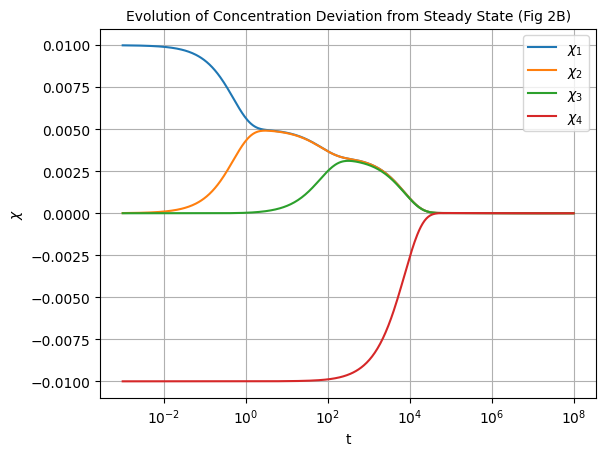

In [ ]:
#Stoichiometric Coefficient Matrix N
N = np.array(
    [
      [1, -1, 0, 0, 0 ],
      [0, 1, -1, 0, 0 ],
      [0, 0, 1, -1, 0 ],
      [0, 0, 0, 1, -1 ]
    ]
)

#Reaction rates coefficient matrix
S = np.array(
    [
        [-km[1] ,      0,       0,      0],
        [ kp[2] , -km[2],       0,      0],
        [      0, kp[3],   -km[3],      0],
        [      0,      0,   kp[4], -km[4]],
        [      0,      0,       0,  kp[5]]
    ]
)

#ODE Matrix
A = N @ S

#Initial condition of the system
chi_0 = np.array([0.01, 0.0, 0.0, -0.01])

#CRN System ODE right-hand side: dchi/dt = N @ (S @ chi)
def CRN_system(t, chi):
    return N @ (S @ chi )

# Log-spaced output times to capture all timescales (1e-3 to 1e 8)
t_vals = np.logspace(-3, 8, 500)

#Obtaining the trajectory of concentrations
sol = solve_ivp(CRN_system, (0, t_vals[-1]), chi_0, method="Radau", t_eval = t_vals, jac = A, rtol=1e-8, atol = 1e-12)

#Plotting
for i in range(4):
    plt.semilogx(sol.t, sol.y[i], label=fr"$\chi_{i+1}$")
plt.xlabel("t")
plt.ylabel(r"$\chi$")
plt.title('Evolution of Concentration Deviation from Steady State (Fig 2B)', fontsize = 10)
plt.legend()
plt.grid(True)
plt.show()

Checking for eigenvalues (See eigenvalue column of Fig 2C)

In [ ]:
eigenvalues, eigenvectors = np.linalg.eig(A)
order = np.argsort(-eigenvalues.real)[::-1]
eigenvalues  = eigenvalues.real[order]
eigenvectors = eigenvectors.real[:, order]

for eig in range(4):
  print(f"eigenvalue No. {eig + 1} = {eigenvalues[eig]: .16f}")

eigenvalue No. 1 = -2.0050381864724529
eigenvalue No. 2 = -0.0150297420974857
eigenvalue No. 3 = -0.0001335720535634
eigenvalue No. 4 = -0.0000004993764987


Timescales available in the reaction network

In [ ]:
for eig in range(4):
  print(f"Timescale No. {eig + 1} = {np.abs(1/eigenvalues[eig])} sec")

Timescale No. 1 = 0.49874361832446773 sec
Timescale No. 2 = 66.53474114950299 sec
Timescale No. 3 = 7486.595985629599 sec
Timescale No. 4 = 2002497.119168318 sec


Eigenmodes from the eigenvectors

In [ ]:
for eig in range(4):
  print(f"eigenvector for eigenvalue {eigenvalues[eig]: .16f} = {eigenvectors[:, eig]}")

eigenvector for eigenvalue -2.0050381864724529 = [ 7.05323662e-01 -7.08876509e-01  3.55337582e-03 -1.77231279e-07]
eigenvector for eigenvalue -0.0150297420974857 = [-0.40949547 -0.40334127  0.81829044 -0.00548131]
eigenvector for eigenvalue -0.0001335720535634 = [-0.29018882 -0.29015035 -0.28242766  0.86708583]
eigenvector for eigenvalue -0.0000004993764987 = [-0.50062205 -0.5006223  -0.50062237 -0.49812862]


Solving for the concentration pools using the equation

$$
\mathbf{P} \mathbf{\Phi} = \mathbf{I}
$$

In [ ]:
Phi = eigenvectors

Concentration_Pools = np.linalg.inv(Phi)

print(np.round(Concentration_Pools, 2))

[[ 0.71 -0.71  0.   -0.  ]
 [-0.41 -0.4   0.82 -0.01]
 [-0.29 -0.29 -0.28  0.87]
 [-0.5  -0.5  -0.5  -0.5 ]]


Checking for active modes

In [ ]:
Phi = eigenvectors / np.linalg.norm(eigenvectors, axis = 0)       # unit-length columns
alpha = np.linalg.solve(Phi, chi_0)

def active_modes(t_ref, a = 2.0, eps = 0.03):
    t1 = t_ref / a
    t2 = t_ref * a
    c = np.abs(alpha) * np.abs(np.exp(eigenvalues * t2) - np.exp(eigenvalues * t1))
    return np.where(c > eps * c.max())[0]

for t_ref in np.logspace(-2, 7, 40):
    print(f"t = {t_ref:.3g} s, active modes = {active_modes(t_ref) + 1}")

t = 0.01 s, active modes = [1]
t = 0.017 s, active modes = [1]
t = 0.0289 s, active modes = [1]
t = 0.0492 s, active modes = [1]
t = 0.0838 s, active modes = [1]
t = 0.143 s, active modes = [1]
t = 0.242 s, active modes = [1]
t = 0.412 s, active modes = [1]
t = 0.702 s, active modes = [1]
t = 1.19 s, active modes = [1 2]
t = 2.03 s, active modes = [1 2]
t = 3.46 s, active modes = [1 2]
t = 5.88 s, active modes = [1 2]
t = 10 s, active modes = [2 3]
t = 17 s, active modes = [2 3]
t = 28.9 s, active modes = [2 3]
t = 49.2 s, active modes = [2 3]
t = 83.8 s, active modes = [2 3]
t = 143 s, active modes = [2 3]
t = 242 s, active modes = [2 3]
t = 412 s, active modes = [2 3]
t = 702 s, active modes = [3]
t = 1.19e+03 s, active modes = [3]
t = 2.03e+03 s, active modes = [3]
t = 3.46e+03 s, active modes = [3]
t = 5.88e+03 s, active modes = [3]
t = 1e+04 s, active modes = [3]
t = 1.7e+04 s, active modes = [3]
t = 2.89e+04 s, active modes = [3]
t = 4.92e+04 s, active modes = [3]
t = 8.38e+04 s,

Concentration Pools (Pooling Matrix P (Normalized) of Fig 2C):

In [ ]:
for i in range(4):
  print(f"Concentration Pool No. {i + 1} = {np.round(Concentration_Pools[i], 2)}")

Concentration Pool No. 1 = [ 0.71 -0.71  0.   -0.  ]
Concentration Pool No. 2 = [-0.41 -0.4   0.82 -0.01]
Concentration Pool No. 3 = [-0.29 -0.29 -0.28  0.87]
Concentration Pool No. 4 = [-0.5 -0.5 -0.5 -0.5]


In [ ]:
#Active modes per interval
active = {1: [0], 2: [0, 1], 3: [1], 4: [1, 2], 5: [2], 6: [2, 3], 7: [3]}

for k, modes in active.items():
    P = np.linalg.pinv(Phi[:, modes])
    P = P / np.linalg.norm(P)
    print(f"Interval {k}:\n{np.round(P, 2)}")

Interval 1:
[[ 0.71 -0.71  0.   -0.  ]]
Interval 2:
[[ 0.5  -0.5   0.   -0.  ]
 [-0.29 -0.29  0.58 -0.  ]]
Interval 3:
[[-0.41 -0.4   0.82 -0.01]]
Interval 4:
[[-0.29 -0.29  0.58 -0.  ]
 [-0.21 -0.21 -0.2   0.61]]
Interval 5:
[[-0.29 -0.29 -0.28  0.87]]
Interval 6:
[[-0.21 -0.21 -0.2   0.61]
 [-0.35 -0.35 -0.35 -0.35]]
Interval 7:
[[-0.5 -0.5 -0.5 -0.5]]


Double checking

In [ ]:
print(np.round(Concentration_Pools @ Phi, 10))   # identity matrix

[[ 1. -0.  0.  0.]
 [-0.  1. -0. -0.]
 [-0.  0.  1. -0.]
 [-0.  0. -0.  1.]]


**Toy Model 2**

Rate constants source (Github repository of the author): https://github.com/akbari84/Dynamic-Mode-Analysis/blob/main/Supplementary%20Code%201.tar

In [ ]:
#Rate Constants
kp  = {1: 1e-3, 2: 1.0, 3: 1e-2, 4: 1.0, 5: 1e-3, 6: 1.0, 7: 1.0}       # k_r^+
km  = {1: 1e-3, 2: 1.0, 3: 1e-2, 4: 1.0, 5: 1e-3, 6: 1.0, 7: 1.0}       # k_r^-

#initial conditions (perturbations)
chi_0 = np.array([0.0, -0.001, 0.0, 0.001, 0.01, -0.01])

x_out = np.array([0.2, 0.0, 0.0, 0.1, 0.2, 0.1])


#Stoichiometric Coefficient Matrix N (6 species x 7 reactions)
N = np.array(
    [
      [1, -1,  0,  0,  0, 0, 0],
      [0,  2, -1,  0,  0, 0, 0],
      [0,  0,  1, -1,  0, 0, 0],
      [0,  0,  0,  1, -1, 0, 0],
      [0, -1,  0,  1,  0, 1, 0],
      [0,  1,  0, -1,  0, 0, 1]
    ]
)

#Solving for steady state values
def fluxes(x):
    return np.array([
        kp[1]*x_out[0] - km[1]*x[0],
        kp[2]*x[0]*x[4] - km[2]*x[1]**2*x[5],
        kp[3]*x[1] - km[3]*x[2],
        kp[4]*x[2]*x[5] - km[4]*x[3]*x[4],
        kp[5]*x[3] - km[5]*x_out[3],
        kp[6]*x_out[4] - km[6]*x[4],
        kp[7]*x_out[5] - km[7]*x[5]
    ])

x_guess = np.array([x_out[0], 0.0, 0.0, x_out[3], x_out[4], x_out[5]])
x_ss = fsolve(lambda x: N @ fluxes(x), x_guess, xtol = 1e-12)
x1, x2, x3, x4, x5, x6 = x_ss


#Reaction rates coefficient matrix S (7 reactions x 6 species) = dv/dx at steady state
S = np.array(
    [
        [-km[1],          0,          0,          0,          0,          0     ],
        [kp[2]*x5, -2*km[2]*x2*x6,    0,          0,     kp[2]*x1,  -km[2]*x2**2],
        [     0,      kp[3],      -km[3],         0,          0,          0     ],
        [     0,          0,    kp[4]*x6,  -km[4]*x5,  -km[4]*x4,   kp[4]*x3    ],
        [     0,          0,          0,      kp[5],          0,          0     ],
        [     0,          0,          0,          0,     -km[6],          0     ],
        [     0,          0,          0,          0,          0,     -km[7]     ]
    ]
)

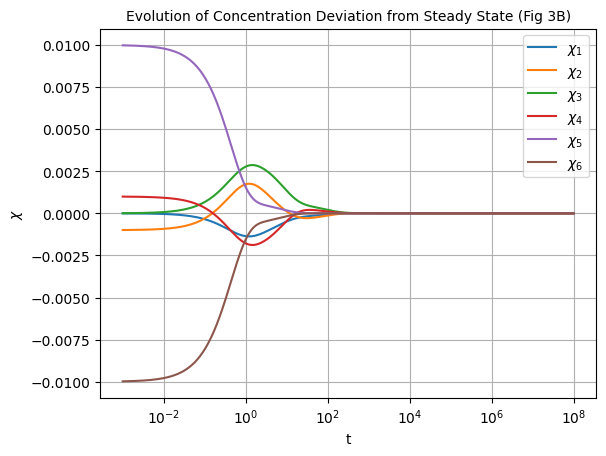

In [ ]:
#ODE Matrix
A = N @ S

#CRN System ODE right-hand side: dchi/dt = N @ (S @ chi)
def CRN_system(t, chi):
    return N @ (S @ chi )

# Log-spaced output times to capture all timescales (1e-3 to 1e 8)
t_vals = np.logspace(-3, 8, 500)

#Obtaining the trajectory of concentrations
sol = solve_ivp(CRN_system, (0, t_vals[-1]), chi_0, method="Radau", t_eval = t_vals, jac = A, rtol=1e-8, atol = 1e-12)

#Plotting
for i in range(6):
    plt.semilogx(sol.t, sol.y[i], label=fr"$\chi_{i+1}$")
plt.xlabel("t")
plt.ylabel(r"$\chi$")
plt.title('Evolution of Concentration Deviation from Steady State (Fig 3B)', fontsize = 10)
plt.legend()
plt.grid(True)
plt.show()

Checking for eigenvalues (See Fig 3C)

In [ ]:
eigenvalues, eigenvectors = np.linalg.eig(A)
order = np.argsort(-eigenvalues.real)[::-1]
eigenvalues  = eigenvalues.real[order]
eigenvectors = eigenvectors.real[:, order]

for eig in range(6):
  print(f"eigenvalue No. {eig + 1} = {eigenvalues[eig]: .16f}")

eigenvalue No. 1 = -2.3086803339125441
eigenvalue No. 2 = -1.0000000000000002
eigenvalue No. 3 = -0.3792206197698952
eigenvalue No. 4 = -0.1419500363648599
eigenvalue No. 5 = -0.0117968923819702
eigenvalue No. 6 = -0.0004279846169495


Checking for eigenmodes (See Fig 3C)

In [ ]:
for eig in range(6):
  print(f"eigenvector for eigenvalue {eigenvalues[eig]: .16f} = {eigenvectors[:, eig]}")

eigenvector for eigenvalue -2.3086803339125441 = [-0.12788188  0.25575254  0.23276783 -0.2329683  -0.63631037  0.63631037]
eigenvector for eigenvalue -1.0000000000000002 = [ 6.88832619e-04 -1.39735320e-03  7.09209413e-04 -6.88832619e-04
  8.94754595e-01  4.46554375e-01]
eigenvector for eigenvalue -0.3792206197698952 = [ 0.3791637  -0.78649903  0.35766015 -0.32835468 -0.03095628  0.03095628]
eigenvector for eigenvalue -0.1419500363648599 = [-0.20493902  0.39036482  0.62636742 -0.61406761  0.13453647 -0.13453647]
eigenvector for eigenvalue -0.0117968923819702 = [-0.28184795 -0.53229939  0.70426487  0.37580311 -0.00102653  0.00102653]
eigenvector for eigenvalue -0.0004279846169495 = [ 3.15351137e-01  6.28098959e-01  6.37294430e-01  3.16071048e-01
  3.61337850e-04 -3.61337850e-04]


In toy model 2, we solve for the concentration pools using the equation

$$
\mathbf{P} \mathbf{\Phi}_{\text{act}} = \mathbf{I}
$$

Since some modes are active in a time interval, we use the columns of those modes, $\mathbf{\Phi}_{\text{act}}$, and and so the pseudo-inverse $\mathbf{P} = \mathbf{\Phi}_{\text{act}}^{\dagger}$. This is the definition in the paper.


*Determining the active modes*

The modes of $\mathbf{\Phi}$ are not all relevant at the same time. A mode $e^{\lambda_i t}$ changes appreciably in a time window only when $t$ is close to its timescale $T_i = 1/|\lambda_i|$. If $t \ll T_i$, the mode is still frozen ($e^{\lambda_i t} \approx 1$). If $t \gg T_i$, it has already decayed ($e^{\lambda_i t} \approx 0$). The modes that are neither frozen nor decayed are the active modes, and their number is the dynamic dimensionality $\nu$.

A mode can also be inactive if the perturbation does not excite it, that is, if its amplitude $\alpha_i$ is close to zero. The amplitudes follow from the initial condition,

$$
\boldsymbol{\alpha} = \mathbf{\Phi}^{-1} \boldsymbol{\chi}_0 .
$$

To decide this numerically, we measure how much each mode changes across a window $[t_1, t_2] = [t/a,\ a\,t]$,

$$
c_i = |\alpha_i| \left| e^{\lambda_i t_2} - e^{\lambda_i t_1} \right|,
$$

and call mode $i$ active if $c_i > \varepsilon \max_j c_j$. The window factor $a = 2$ and the threshold $\varepsilon = 0.03$ are chosen here, and the resulting intervals depend on them. In the paper, the same decision is made from the data alone: the number of singular values of the window data matrix above a tolerance gives $\nu$.

In [ ]:
Phi = eigenvectors / np.linalg.norm(eigenvectors, axis = 0)       # unit-length columns

In [ ]:
alpha = np.linalg.solve(Phi, chi_0)

def active_modes(t_ref, a = 2.0, eps = 0.03):
    t1 = t_ref / a
    t2 = t_ref * a
    c = np.abs(alpha) * np.abs(np.exp(eigenvalues * t2) - np.exp(eigenvalues * t1))
    return np.where(c > eps * c.max())[0]

for t_ref in np.logspace(-2, 7, 40):
    print(f"t = {t_ref:.3f} s, active modes = {active_modes(t_ref) + 1}")

t = 0.010 s, active modes = [1]
t = 0.017 s, active modes = [1]
t = 0.029 s, active modes = [1]
t = 0.049 s, active modes = [1]
t = 0.084 s, active modes = [1]
t = 0.143 s, active modes = [1 4]
t = 0.242 s, active modes = [1 4]
t = 0.412 s, active modes = [1 3 4]
t = 0.702 s, active modes = [1 3 4]
t = 1.194 s, active modes = [1 3 4]
t = 2.031 s, active modes = [1 3 4]
t = 3.455 s, active modes = [1 3 4]
t = 5.878 s, active modes = [3 4 5]
t = 10.000 s, active modes = [3 4 5]
t = 17.013 s, active modes = [3 4 5]
t = 28.943 s, active modes = [4 5]
t = 49.239 s, active modes = [4 5]
t = 83.768 s, active modes = [4 5]
t = 142.510 s, active modes = [5]
t = 242.446 s, active modes = [5]
t = 412.463 s, active modes = [5 6]
t = 701.704 s, active modes = [5 6]
t = 1193.777 s, active modes = [5 6]
t = 2030.918 s, active modes = [6]
t = 3455.107 s, active modes = [6]
t = 5878.016 s, active modes = [6]
t = 10000.000 s, active modes = [6]
t = 17012.543 s, active modes = [6]
t = 28942.661 s, active

In [ ]:
#Active modes per interval
active = {1: [0], 2: [0, 3], 3: [3, 0, 2], 4: [3], 5: [3, 4], 6: [4], 7: [4, 5], 8: [5]}

for k, modes in active.items():
    P = np.linalg.pinv(Phi[:, modes])
    P = P / np.linalg.norm(P)
    print(f"Interval {k}:\n{np.round(P, 2)}")

Interval 1:
[[-0.13  0.26  0.23 -0.23 -0.64  0.64]]
Interval 2:
[[-0.06  0.12  0.06 -0.06 -0.49  0.49]
 [-0.13  0.24  0.42 -0.41  0.21 -0.21]]
Interval 3:
[[-0.11  0.22  0.33 -0.33  0.18 -0.18]
 [-0.03  0.07  0.06 -0.06 -0.4   0.4 ]
 [ 0.22 -0.45  0.19 -0.18 -0.04  0.04]]
Interval 4:
[[-0.2   0.39  0.63 -0.61  0.13 -0.13]]
Interval 5:
[[-0.13  0.3   0.41 -0.45  0.1  -0.1 ]
 [-0.19 -0.39  0.47  0.29 -0.01  0.01]]
Interval 6:
[[-0.28 -0.53  0.7   0.38 -0.    0.  ]]
Interval 7:
[[-0.23 -0.45  0.44  0.24 -0.    0.  ]
 [ 0.25  0.5   0.38  0.19  0.   -0.  ]]
Interval 8:
[[ 0.32  0.63  0.64  0.32  0.   -0.  ]]
